In [1]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt

Récupérer les archives météo:

In [2]:
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 22.0,
    "longitude": 78.0,
    "start_date": "2020-05-15",
    "end_date": "2020-06-18",
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "cloud_cover",
        "cloud_cover_low",
        "cloud_cover_mid",
        "cloud_cover_high",
        "shortwave_radiation",
        "direct_radiation",
        "diffuse_radiation",
        "wind_speed_10m",
        "precipitation"
    ],
    "timezone": "Asia/Kolkata"
}

reponse = requests.get(url, params=params)
donnees = reponse.json()
print(reponse.status_code)

200


In [3]:
meteo = pd.DataFrame(donnees["hourly"])
meteo["time"] = pd.to_datetime(meteo["time"])
meteo = meteo.set_index("time")

print(meteo.shape)
meteo.head()

(840, 11)


,temperature_2m,relative_humidity_2m,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high,shortwave_radiation,direct_radiation,diffuse_radiation,wind_speed_10m,precipitation
time,,,,,,,,,,,
2020-05-15 00:00:00,30.3,44,32,0,32,1,0.0,0.0,0.0,14.1,0.0
2020-05-15 01:00:00,29.9,46,30,0,30,0,0.0,0.0,0.0,13.0,0.0
2020-05-15 02:00:00,29.5,46,29,0,29,0,0.0,0.0,0.0,12.2,0.0
2020-05-15 03:00:00,29.1,47,29,0,29,0,0.0,0.0,0.0,13.2,0.0
2020-05-15 04:00:00,28.4,49,52,0,48,21,0.0,0.0,0.0,14.1,0.0


In [4]:
# Ré-échantillonnage horaire → 15 min par interpolation
meteo_15 = meteo.resample("15min").interpolate(method="linear")
print(meteo_15.shape)

(3357, 11)


In [5]:
prod = pd.read_csv("data/dataset_jour.csv", index_col="DATE_TIME", parse_dates=True)

# On garde la production et on ajoute les variables météo prévues
data = prod[["AC_POWER_TOTAL"]].join(meteo_15, how="inner")

print(data.shape)
print(data.isna().sum().sum(), "valeurs manquantes")
data.head()

(1650, 12)
0 valeurs manquantes


,AC_POWER_TOTAL,temperature_2m,relative_humidity_2m,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high,shortwave_radiation,direct_radiation,diffuse_radiation,wind_speed_10m,precipitation
DATE_TIME,,,,,,,,,,,,
2020-05-15 06:15:00,593.338690,28.825,61.0,23.5,0.0,20.50,5.5,56.25,21.75,34.50,5.825,0.0
2020-05-15 06:30:00,1480.194643,29.250,60.0,21.0,0.0,16.00,8.0,89.50,38.50,51.00,5.550,0.0
2020-05-15 06:45:00,2790.448214,29.675,59.0,18.5,0.0,11.50,10.5,122.75,55.25,67.50,5.275,0.0
2020-05-15 07:00:00,4052.662143,30.100,58.0,16.0,0.0,7.00,13.0,156.00,72.00,84.00,5.000,0.0
2020-05-15 07:15:00,4368.722619,30.650,55.5,12.5,0.0,5.75,10.0,211.75,114.00,97.75,6.500,0.0


In [6]:
corr = data.corr()["AC_POWER_TOTAL"].drop("AC_POWER_TOTAL").sort_values(ascending=False)
print(corr)

shortwave_radiation     0.706743
diffuse_radiation       0.676955
direct_radiation        0.617694
temperature_2m          0.317225
wind_speed_10m          0.235247
cloud_cover_low         0.075213
precipitation           0.026694
cloud_cover_high       -0.022082
cloud_cover            -0.038969
cloud_cover_mid        -0.061070
relative_humidity_2m   -0.193227
Name: AC_POWER_TOTAL, dtype: float64


In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Variables temporelles (connues à l'avance, donc légitimes)
data["heure"] = data.index.hour + data.index.minute / 60
data["heure_sin"] = np.sin(2 * np.pi * data["heure"] / 24)
data["heure_cos"] = np.cos(2 * np.pi * data["heure"] / 24)

cible = "AC_POWER_TOTAL"
features = [c for c in data.columns if c != cible]

split = int(len(data) * 0.8)
Xtr, ytr = data[features].iloc[:split], data[cible].iloc[:split]
Xte, yte = data[features].iloc[split:], data[cible].iloc[split:]

rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(Xtr, ytr)
pred = rf.predict(Xte)

rmse = np.sqrt(mean_squared_error(yte, pred))
mae = mean_absolute_error(yte, pred)
print(f"RMSE : {rmse:.0f} kW | MAE : {mae:.0f} kW")
print(f"Skill score vs persistance (3075 kW) : {100*(1-rmse/3075):.1f} %")

RMSE : 4074 kW | MAE : 3069 kW
Skill score vs persistance (3075 kW) : -32.5 %


**Passage à une vraie tâche de prévision**

**Démarche**

Les notebooks précédents aboutissaient à un modèle de nowcasting : la
production était estimée à partir de l'irradiance mesurée au même instant,
information indisponible en situation de prévision.

Pour traiter le problème réel, les mesures sur site sont remplacées par des
données météorologiques issues des archives Open-Meteo (réanalyse ERA5),
pour la localisation et la période du jeu de données : rayonnement global,
direct et diffus, couverture nuageuse à trois altitudes, température,
humidité, vent et précipitations.

Les données sont horaires et ont été ré-échantillonnées au pas de 15 minutes
par interpolation linéaire, puis jointes à la production mesurée.
Jeu obtenu : 1650 lignes, aucune valeur manquante.

**Corrélations avec la production**

| Variable | Corrélation |
|---|---|
| shortwave_radiation | 0,707 |
| diffuse_radiation | 0,677 |
| direct_radiation | 0,618 |
| temperature_2m | 0,317 |
| relative_humidity_2m | -0,193 |
| cloud_cover | -0,039 |

Le rayonnement issu de la réanalyse est nettement moins corrélé à la
production (0,707) que le capteur local (0,991). Cet écart était attendu :
une réanalyse fournit une valeur moyenne sur une maille de plusieurs
dizaines de kilomètres, là où le capteur mesure l'irradiance au pied des
modules.

La couverture nuageuse apparaît quasi décorrélée (-0,039). Deux causes
probables : les coordonnées exactes de la centrale ne sont pas fournies
dans le jeu de données d'origine, et son effet n'est pas linéaire —
il dépend de l'heure et de la hauteur du soleil.

**Résultat**

Random Forest entraîné uniquement sur des variables disponibles à l'avance
(météo prévue + encodage horaire), séparation temporelle 80 / 20 :

| Modèle | RMSE (kW) | Skill score |
|---|---|---|
| Persistance | 3075 | 0 % |
| Random Forest (météo prévue) | 4074 | -32,5 % |

Le modèle est moins performant que la persistance. Ce résultat confirme la
difficulté réelle de la tâche : la prévision de production photovoltaïque
dépend essentiellement de la prévision de la couverture nuageuse, et la
résolution spatiale d'une réanalyse est insuffisante pour capter la
variabilité locale observée à la centrale.

**Pistes d'amélioration**

- Affiner la localisation du site.
- Combiner les variables météo prévues avec l'état récent mesuré
  (production des dernières heures), ce qui correspond à la pratique

In [8]:
# Ajouter l'état récent mesuré (disponible en opérationnel)
data["prod_lag_1"] = data[cible].shift(1)
data["prod_lag_2"] = data[cible].shift(2)
data["prod_lag_4"] = data[cible].shift(4)
data["prod_moy_1h"] = data[cible].rolling(4).mean().shift(1)

d2 = data.dropna()
features2 = [c for c in d2.columns if c != cible]

split2 = int(len(d2) * 0.8)
Xtr2, ytr2 = d2[features2].iloc[:split2], d2[cible].iloc[:split2]
Xte2, yte2 = d2[features2].iloc[split2:], d2[cible].iloc[split2:]

rf2 = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf2.fit(Xtr2, ytr2)
pred2 = rf2.predict(Xte2)

rmse2 = np.sqrt(mean_squared_error(yte2, pred2))
print(f"RMSE : {rmse2:.0f} kW | Skill score : {100*(1-rmse2/3075):.1f} %")

RMSE : 2891 kW | Skill score : 6.0 %


In [9]:
# Prédire la production dans 1 heure (4 pas de 15 min)
d3 = data.copy()
d3["cible_1h"] = d3[cible].shift(-4)
d3 = d3.dropna()

features3 = [c for c in d3.columns if c not in [cible, "cible_1h"]]

split3 = int(len(d3) * 0.8)
Xtr3, ytr3 = d3[features3].iloc[:split3], d3["cible_1h"].iloc[:split3]
Xte3, yte3 = d3[features3].iloc[split3:], d3["cible_1h"].iloc[split3:]

# Persistance à 1h : la production actuelle
pers_1h = Xte3[cible] if cible in features3 else d3[cible].iloc[split3:]
rmse_pers = np.sqrt(mean_squared_error(yte3, pers_1h))

rf3 = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf3.fit(Xtr3, ytr3)
pred3 = rf3.predict(Xte3)
rmse3 = np.sqrt(mean_squared_error(yte3, pred3))

print(f"Persistance 1h : {rmse_pers:.0f} kW")
print(f"Modèle 1h      : {rmse3:.0f} kW")
print(f"Skill score    : {100*(1-rmse3/rmse_pers):.1f} %")

Persistance 1h : 5380 kW
Modèle 1h      : 3716 kW
Skill score    : 30.9 %


In [10]:
print(cible in features3)
print(len(features3))

False
18


In [11]:
print(features3)

['temperature_2m', 'relative_humidity_2m', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'wind_speed_10m', 'precipitation', 'heure', 'heure_sin', 'heure_cos', 'prod_lag_1', 'prod_lag_2', 'prod_lag_4', 'prod_moy_1h']


In [12]:
features3 = [c for c in d3.columns if c != "cible_1h"]
print(cible in features3, len(features3))

split3 = int(len(d3) * 0.8)
Xtr3, ytr3 = d3[features3].iloc[:split3], d3["cible_1h"].iloc[:split3]
Xte3, yte3 = d3[features3].iloc[split3:], d3["cible_1h"].iloc[split3:]

pers_1h = d3[cible].iloc[split3:]
rmse_pers = np.sqrt(mean_squared_error(yte3, pers_1h))

rf3 = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf3.fit(Xtr3, ytr3)
pred3 = rf3.predict(Xte3)
rmse3 = np.sqrt(mean_squared_error(yte3, pred3))

print(f"Persistance 1h : {rmse_pers:.0f} kW")
print(f"Modèle 1h      : {rmse3:.0f} kW")
print(f"Skill score    : {100*(1-rmse3/rmse_pers):.1f} %")

True 19
Persistance 1h : 5380 kW
Modèle 1h      : 3712 kW
Skill score    : 31.0 %


**Prévision à 1 heure**

Cible décalée de 4 pas. Variables : météo prévue Open-Meteo, encodage
horaire, état récent de la centrale (production actuelle et retards).
Référence : persistance à 1 h.

| Modèle | RMSE (kW) | Skill score |
|---|---|---|
| Persistance | 5380 | 0 % |
| Random Forest | 3712 | 31,0 % |

Gain de 31 %, conforme à ce qui se pratique en prévision PV
intrajournalière. L'ajout de la production instantanée n'apporte rien de
plus que le retard à 15 min : les deux variables sont redondantes.

À comparer au nowcasting (RMSE 614, skill 80 %) : l'écart mesure la
difficulté propre à la prévision, qui suppose d'anticiper la couverture
nuageuse.

Dégradation du skill score selon l’horizon:

In [13]:
horizons = [1, 2, 4, 8, 12, 24]  # 15 min à 6 h
resultats = []

for h in horizons:
    dh = data.copy()
    dh["cible"] = dh[cible].shift(-h)
    dh = dh.dropna()

    feats = [c for c in dh.columns if c != "cible"]
    s = int(len(dh) * 0.8)

    Xtr, ytr = dh[feats].iloc[:s], dh["cible"].iloc[:s]
    Xte, yte = dh[feats].iloc[s:], dh["cible"].iloc[s:]

    pers = dh[cible].iloc[s:]
    rmse_p = np.sqrt(mean_squared_error(yte, pers))

    m = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
    m.fit(Xtr, ytr)
    rmse_m = np.sqrt(mean_squared_error(yte, m.predict(Xte)))

    resultats.append({
        "horizon_min": h * 15,
        "rmse_persistance": rmse_p,
        "rmse_modele": rmse_m,
        "skill": 100 * (1 - rmse_m / rmse_p)
    })

res = pd.DataFrame(resultats)
print(res.round(1))

   horizon_min  rmse_persistance  rmse_modele  skill
0           15            3026.3       2910.0    3.8
1           30            4127.4       3491.4   15.4
2           60            5380.0       3719.9   30.9
3          120            8162.7       3964.1   51.4
4          180           10462.0       4131.9   60.5
5          360           13179.1       4097.9   68.9


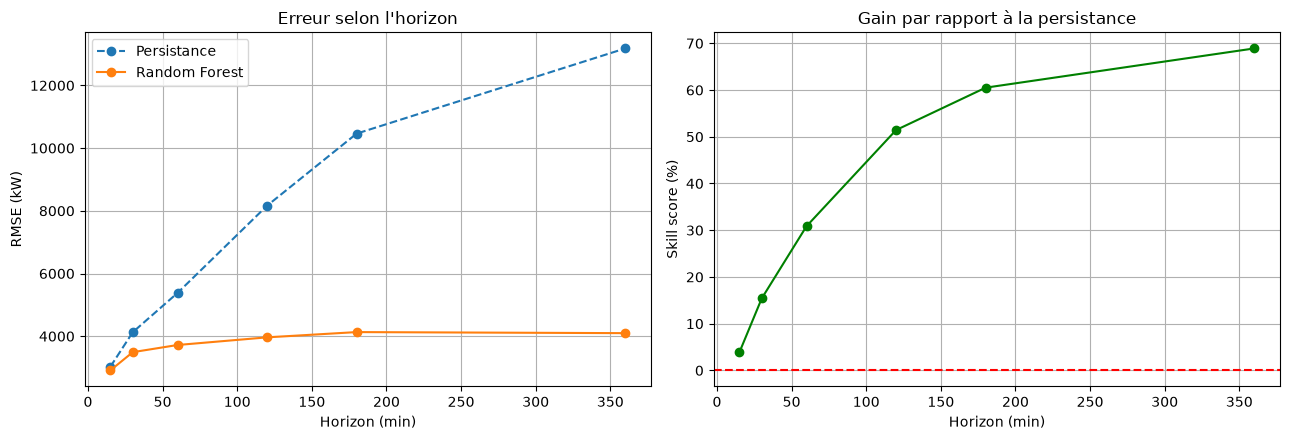

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(res["horizon_min"], res["rmse_persistance"], "o--", label="Persistance")
ax[0].plot(res["horizon_min"], res["rmse_modele"], "o-", label="Random Forest")
ax[0].set_xlabel("Horizon (min)")
ax[0].set_ylabel("RMSE (kW)")
ax[0].set_title("Erreur selon l'horizon")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(res["horizon_min"], res["skill"], "o-", color="green")
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_xlabel("Horizon (min)")
ax[1].set_ylabel("Skill score (%)")
ax[1].set_title("Gain par rapport à la persistance")
ax[1].grid(True)

plt.tight_layout()
plt.show()

**Dégradation selon l'horizon**

| Horizon | RMSE persistance | RMSE modèle | Skill score |
|---|---|---|---|
| 15 min | 3026 | 2910 | 3,8 % |
| 30 min | 4127 | 3491 | 15,4 % |
| 1 h | 5380 | 3720 | 30,9 % |
| 2 h | 8163 | 3964 | 51,4 % |
| 3 h | 10462 | 4132 | 60,5 % |
| 6 h | 13179 | 4098 | 68,9 % |

L'erreur de la persistance croît fortement avec l'horizon, tandis que celle
du modèle reste stable autour de 4000 kW : il s'appuie sur la géométrie
solaire et la météo prévue plutôt que sur l'extrapolation de l'instant
courant.

Le gain est donc faible à très court terme (3,8 % à 15 min, où la
persistance est déjà performante) et devient important au-delà d'une heure.

Comparer Random Forest et XGBoost à 1 h:

In [16]:
from xgboost import XGBRegressor

d = data.copy()
d["cible"] = d[cible].shift(-4)
d = d.dropna()

feats = [c for c in d.columns if c != "cible"]
s = int(len(d) * 0.8)

Xtr, ytr = d[feats].iloc[:s], d["cible"].iloc[:s]
Xte, yte = d[feats].iloc[s:], d["cible"].iloc[s:]

rmse_pers = np.sqrt(mean_squared_error(yte, d[cible].iloc[s:]))

modeles = {
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                            subsample=0.8, colsample_bytree=0.8, random_state=42)
}

for nom, m in modeles.items():
    m.fit(Xtr, ytr)
    r = np.sqrt(mean_squared_error(yte, m.predict(Xte)))
    print(f"{nom:15} RMSE : {r:.0f} kW | Skill : {100*(1-r/rmse_pers):.1f} %")

Random Forest   RMSE : 3712 kW | Skill : 31.0 %
XGBoost         RMSE : 3935 kW | Skill : 26.9 %


Importance des variables:

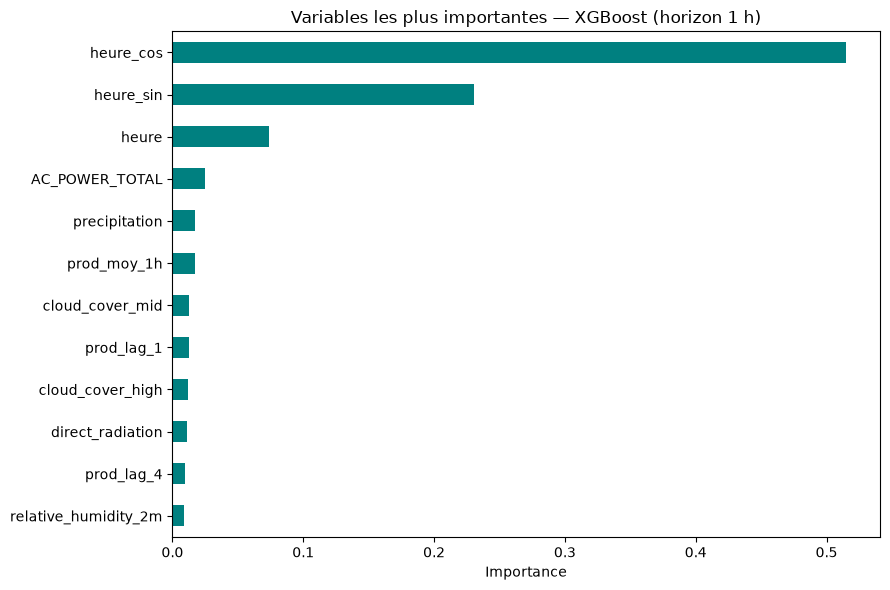

In [17]:
xgb = modeles["XGBoost"]
imp = pd.Series(xgb.feature_importances_, index=feats).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
imp.head(12).sort_values().plot(kind="barh", color="teal")
plt.title("Variables les plus importantes — XGBoost (horizon 1 h)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

**Comparaison Random Forest / XGBoost (horizon 1 h)**

| Modèle | RMSE (kW) | Skill score |
|---|---|---|
| Random Forest | 3712 | 31,0 % |
| XGBoost | 3935 | 26,9 % |

Random Forest reste devant. Sur un jeu d'entraînement réduit (environ 1250
points), le gain habituel du boosting ne se matérialise pas.

L'analyse des importances montre que l'encodage horaire concentre plus de
80 % de l'importance : le modèle apprend principalement le profil journalier
moyen. Les variables météorologiques pèsent chacune environ 1 %, ce qui
limite sa capacité à anticiper les écarts liés à la couverture nuageuse.

Sauvegarde:

In [18]:
import joblib

# Réentraîner le meilleur modèle (Random Forest, horizon 1 h)
rf_final = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf_final.fit(Xtr, ytr)

joblib.dump(rf_final, "modele_rf.pkl")
joblib.dump(feats, "features.pkl")

# Sauvegarder les prédictions sur le test pour le dashboard
sortie = pd.DataFrame({
    "reel": yte,
    "predit": rf_final.predict(Xte),
    "persistance": d[cible].iloc[s:]
}, index=yte.index)

sortie.to_csv("data/predictions.csv")
print(sortie.head())

                             reel        predit   persistance
DATE_TIME                                                    
2020-06-11 08:45:00  10287.671429  13186.837927   7359.114286
2020-06-11 09:00:00  11091.971429  13854.841760   8189.850000
2020-06-11 09:15:00  12068.066071  14185.310830   9038.585715
2020-06-11 09:30:00  12320.907143  15696.532307   9610.560714
2020-06-11 09:45:00  12771.435714  15831.018833  10287.671429


Graphique prévision vs réalité:

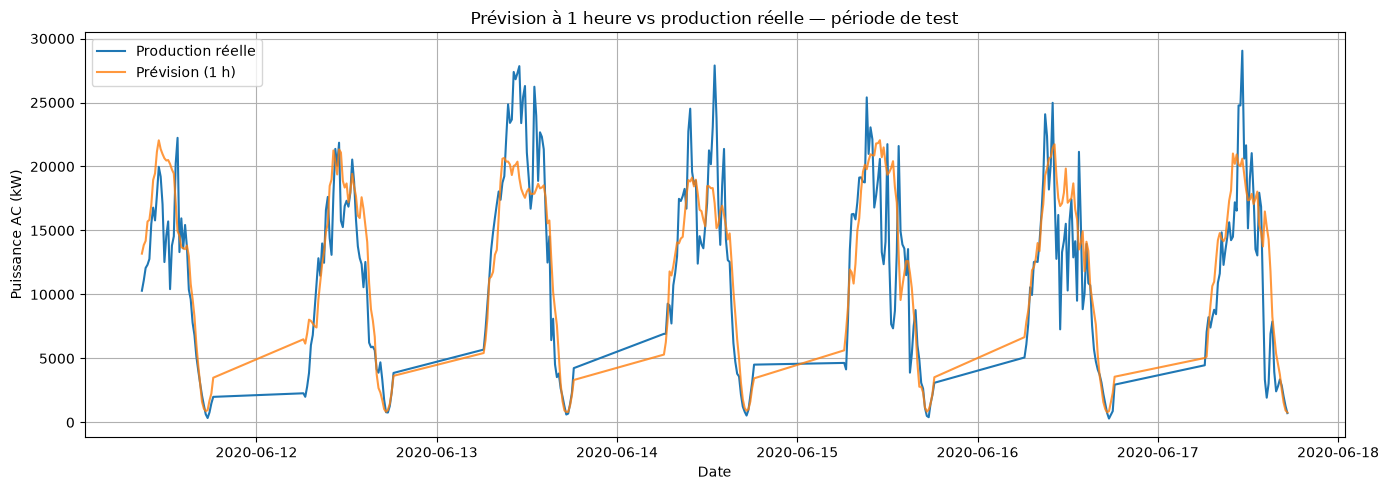

In [19]:
plt.figure(figsize=(14, 5))
plt.plot(sortie.index, sortie["reel"], label="Production réelle", linewidth=1.5)
plt.plot(sortie.index, sortie["predit"], label="Prévision (1 h)", linewidth=1.5, alpha=0.8)
plt.xlabel("Date")
plt.ylabel("Puissance AC (kW)")
plt.title("Prévision à 1 heure vs production réelle — période de test")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Nuage prédiction/réalité:

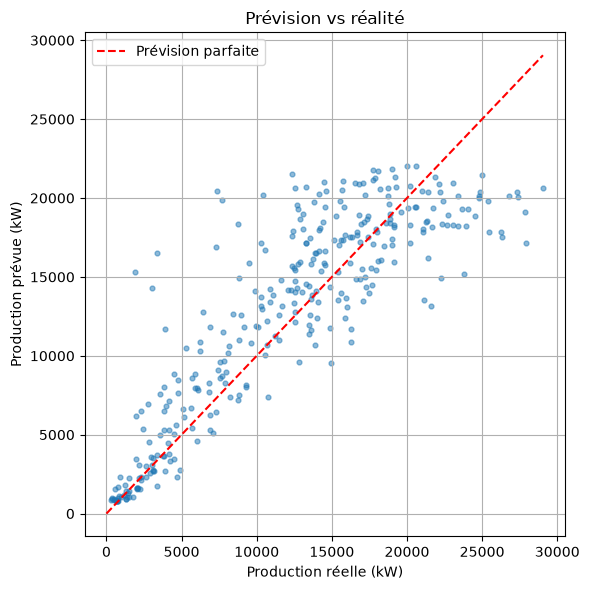

In [20]:
plt.figure(figsize=(6, 6))
plt.scatter(sortie["reel"], sortie["predit"], s=12, alpha=0.5)
lim = [0, max(sortie["reel"].max(), sortie["predit"].max())]
plt.plot(lim, lim, "r--", label="Prévision parfaite")
plt.xlabel("Production réelle (kW)")
plt.ylabel("Production prévue (kW)")
plt.title("Prévision vs réalité")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Analyse des prévisions**

Sur la période de test (11-17 juin), la prévision à 1 h reproduit
correctement l'enveloppe journalière mais reste plus lisse que la
production réelle : les variations rapides liées aux passages nuageux ne
sont pas anticipées.

Le nuage prévision/réalité montre une régression vers la moyenne : les
pics au-delà de 20 000 kW sont sous-estimés, les creux en dessous de
10 000 kW surestimés. Ce comportement est cohérent avec l'analyse des
importances — le modèle s'appuie majoritairement sur le profil horaire et
dispose de peu d'information exploitable sur la couverture nuageuse.